<a href="https://www.kaggle.com/code/mahmudulhasan0king01/brain-tumor-mri-classification-cnn-transfer-l?scriptVersionId=366842685" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

**Brain Tumor MRI Classification using CNN and Transfer Learning**

**Imports and Setup**

In [1]:
import os, random, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
train_dir = test_dir = None
for root, dirs, _ in os.walk("/kaggle/input"):
    if os.path.basename(root).lower() == "training" and "glioma" in dirs:
        train_dir = root
    if os.path.basename(root).lower() == "testing" and "glioma" in dirs:
        test_dir = root
print("Train:", train_dir); print("Test:", test_dir)

for c in sorted(os.listdir(train_dir)):
    print(c, "train:", len(os.listdir(f"{train_dir}/{c}")),
             "test:", len(os.listdir(f"{test_dir}/{c}")))

Train: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Test: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
glioma train: 1400 test: 400
meningioma train: 1400 test: 400
notumor train: 1400 test: 400
pituitary train: 1400 test: 400


**Load data (with validation split)**

In [3]:
IMG = (224, 224); BATCH = 32
kw = dict(image_size=IMG, batch_size=BATCH, label_mode="categorical")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training", seed=SEED, **kw)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation", seed=SEED, **kw)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, shuffle=False, **kw)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary']


**Visualize samples**

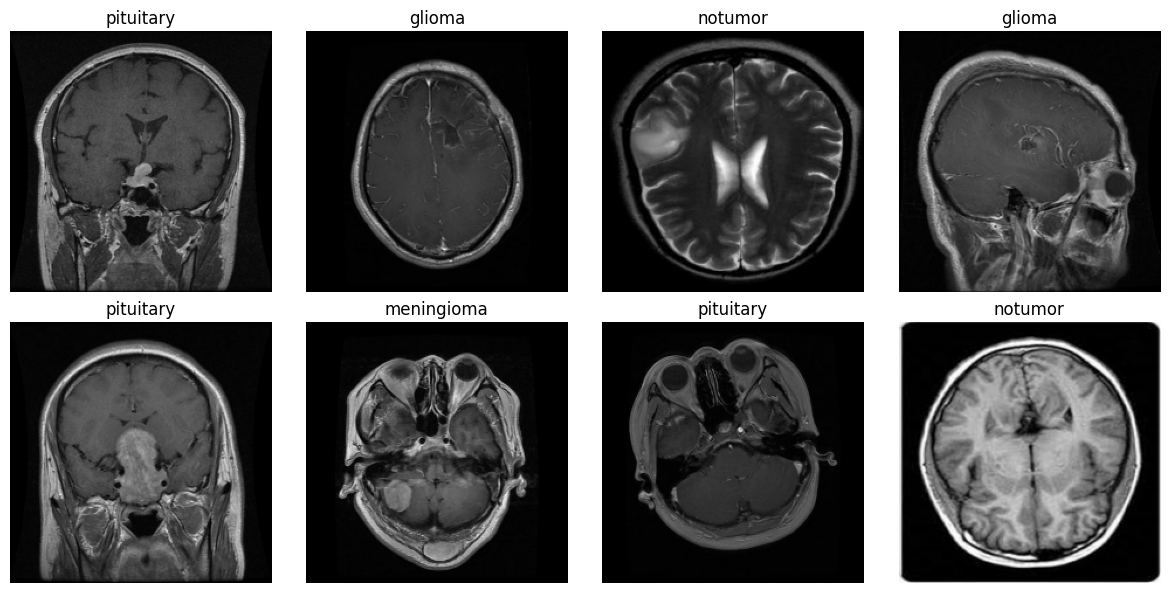

In [4]:
plt.figure(figsize=(12, 6))
for imgs, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy().argmax()]); plt.axis("off")
plt.tight_layout(); plt.show()

**Helper functions (plots and evaluation)**

In [5]:
def plot_history(histories, title):
    acc = sum([h.history["accuracy"] for h in histories], [])
    val_acc = sum([h.history["val_accuracy"] for h in histories], [])
    loss = sum([h.history["loss"] for h in histories], [])
    val_loss = sum([h.history["val_loss"] for h in histories], [])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].legend()
    ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val")
    ax[1].set_title(f"{title} - Loss"); ax[1].legend()
    plt.show()

def evaluate(model, name):
    y_true = np.concatenate([y.numpy().argmax(1) for _, y in test_ds])
    y_pred = model.predict(test_ds, verbose=0).argmax(1)
    print(f"=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    plt.figure(figsize=(6, 5))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{name} - Confusion Matrix"); plt.ylabel("True"); plt.xlabel("Predicted")
    plt.show()
    return (y_true == y_pred).mean()

def get_callbacks(path):
    return [callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_loss"),
            callbacks.ReduceLROnPlateau(patience=2, factor=0.5, verbose=1),
            callbacks.ModelCheckpoint(path, save_best_only=True, monitor="val_loss")]


**Model 1, custom CNN from scratch**

In [6]:
augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)], name="augmentation")

def build_cnn():
    return models.Sequential([
        layers.Input((*IMG, 3)),
        augment,
        layers.Rescaling(1./255),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(256, 3, padding="same", activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="custom_cnn")

cnn = build_cnn()
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

**Train the CNN**

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 169ms/step - accuracy: 0.6752 - loss: 0.8223 - val_accuracy: 0.2625 - val_loss: 1.9475 - learning_rate: 0.0010
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 123ms/step - accuracy: 0.7326 - loss: 0.6804 - val_accuracy: 0.2911 - val_loss: 2.5750 - learning_rate: 0.0010
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 125ms/step - accuracy: 0.7752 - loss: 0.5744 - val_accuracy: 0.4705 - val_loss: 1.4941 - learning_rate: 0.0010
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 126ms/step - accuracy: 0.7987 - loss: 0.5266 - val_accuracy: 0.6804 - val_loss: 0.8302 - learning_rate: 0.0010
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step - accuracy: 0.8275 - loss: 0.4747 - val_accuracy: 0.6687 - val_loss: 0.8545 - learning_rate: 0.0010
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.8284 - loss: 0.4434
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 130ms/step - accuracy: 0.829

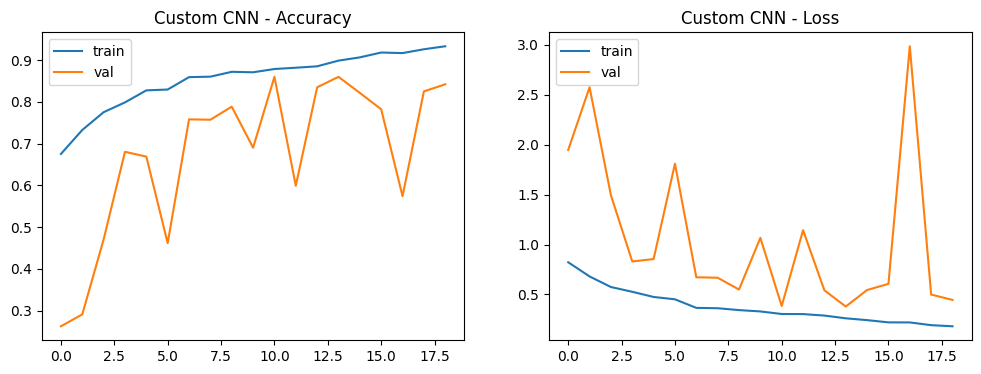

=== Custom CNN ===
              precision    recall  f1-score   support

      glioma     0.9696    0.6375    0.7692       400
  meningioma     0.8423    0.5475    0.6636       400
     notumor     0.8119    0.9925    0.8931       400
   pituitary     0.6803    1.0000    0.8097       400

    accuracy                         0.7944      1600
   macro avg     0.8260    0.7944    0.7839      1600
weighted avg     0.8260    0.7944    0.7839      1600



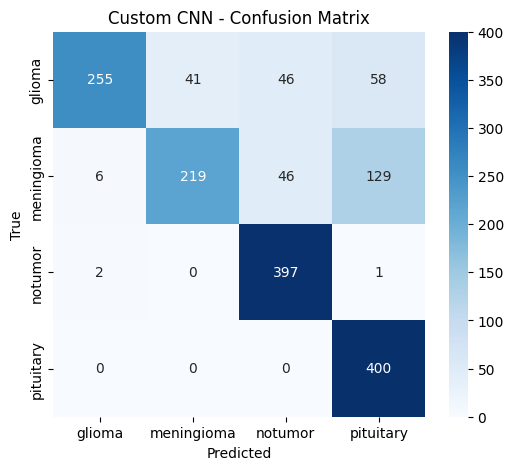

In [7]:
h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=30,
                callbacks=get_callbacks("best_cnn.keras"))
plot_history([h_cnn], "Custom CNN")
cnn_acc = evaluate(cnn, "Custom CNN")

**Model 2, Transfer Learning (EfficientNetB0)**

In [8]:
base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG, 3))
base.trainable = False   # Phase 1: freeze the base

inputs = layers.Input((*IMG, 3))
x = augment(inputs)
x = base(x, training=False)      # EfficientNet has its own built-in preprocessing
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
tl = models.Model(inputs, outputs, name="efficientnetb0_tl")

tl.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
           loss="categorical_crossentropy", metrics=["accuracy"])

# Phase 1: train only the new head
h_tl1 = tl.fit(train_ds, validation_data=val_ds, epochs=10,
               callbacks=get_callbacks("best_tl_phase1.keras"))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


E0000 00:00:1794120848.309105      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_tl_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 120ms/step - accuracy: 0.7531 - loss: 0.7688 - val_accuracy: 0.7937 - val_loss: 0.4897 - learning_rate: 0.0010
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.8319 - loss: 0.4921 - val_accuracy: 0.8464 - val_loss: 0.3752 - learning_rate: 0.0010
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.8480 - loss: 0.4098 - val_accuracy: 0.8777 - val_loss: 0.3319 - learning_rate: 0.0010
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.8663 - loss: 0.3791 - val_accuracy: 0.8696 - val_loss: 0.3610 - learning_rate: 0.0010
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.8790 - loss: 0.3178 - val_accuracy: 0.8929 - val_loss: 0.2823 - learning_rate: 0.0010
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8833 - loss: 0.3039 - val_accuracy: 0.8973 - val_loss: 0.2755 - learning_rate: 0.0010
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.8859 - loss: 0.292

**Fine-tune the top layers**

Epoch 1/15


E0000 00:00:1794120997.462152      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_tl_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 120ms/step - accuracy: 0.9062 - loss: 0.2369 - val_accuracy: 0.9214 - val_loss: 0.2111 - learning_rate: 1.0000e-05
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.9225 - loss: 0.2080 - val_accuracy: 0.9205 - val_loss: 0.2107 - learning_rate: 1.0000e-05
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.9190 - loss: 0.2164 - val_accuracy: 0.9143 - val_loss: 0.2224 - learning_rate: 1.0000e-05
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9248 - loss: 0.1979
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.9225 - loss: 0.2035 - val_accuracy: 0.9187 - val_loss: 0.2118 - learning_rate: 1.0000e-05
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 97ms/step - accuracy: 0.9208 - loss: 0.2016 - val_accuracy: 0.9187 - val_loss: 0.2110 - learning_rate: 5.0000e-06
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0

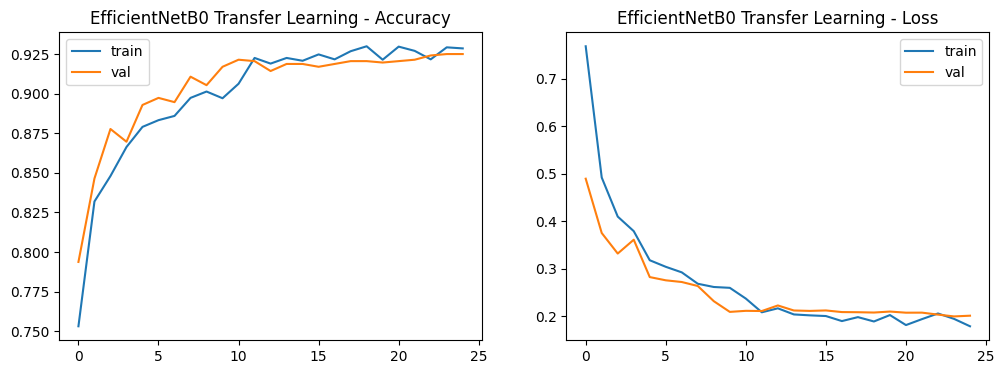

=== EfficientNetB0 Transfer Learning ===
              precision    recall  f1-score   support

      glioma     0.9254    0.6825    0.7856       400
  meningioma     0.8210    0.8025    0.8116       400
     notumor     0.9213    0.9950    0.9567       400
   pituitary     0.8237    0.9925    0.9002       400

    accuracy                         0.8681      1600
   macro avg     0.8728    0.8681    0.8635      1600
weighted avg     0.8728    0.8681    0.8635      1600



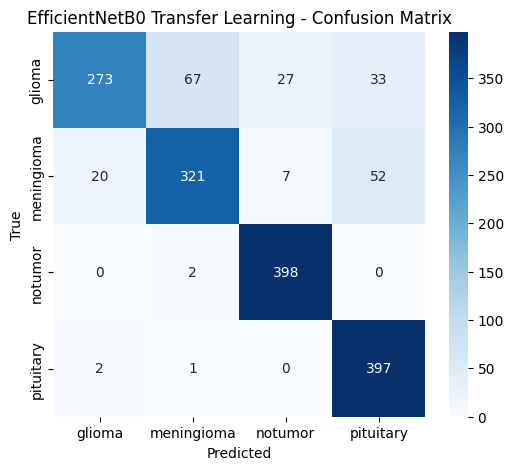

In [9]:
# Phase 2: unfreeze the top ~30 layers (keep BatchNorm layers frozen)
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl.compile(optimizer=tf.keras.optimizers.Adam(1e-5),   # very low learning rate
           loss="categorical_crossentropy", metrics=["accuracy"])

h_tl2 = tl.fit(train_ds, validation_data=val_ds, epochs=15,
               callbacks=get_callbacks("best_tl_final.keras"))
plot_history([h_tl1, h_tl2], "EfficientNetB0 Transfer Learning")
tl_acc = evaluate(tl, "EfficientNetB0 Transfer Learning")

**Compare both models**

Model                               Test Accuracy
Custom CNN                          0.7944
EfficientNetB0 (Transfer Learning)  0.8681


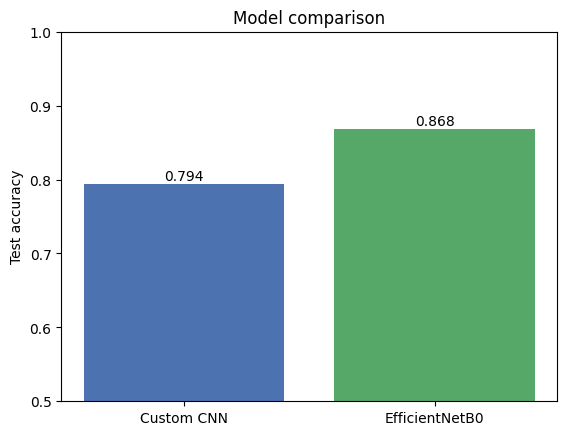

In [10]:
print(f"{'Model':35s} Test Accuracy")
print(f"{'Custom CNN':35s} {cnn_acc:.4f}")
print(f"{'EfficientNetB0 (Transfer Learning)':35s} {tl_acc:.4f}")

plt.bar(["Custom CNN", "EfficientNetB0"], [cnn_acc, tl_acc], color=["#4C72B0", "#55A868"])
plt.ylim(0.5, 1); plt.ylabel("Test accuracy"); plt.title("Model comparison")
for i, v in enumerate([cnn_acc, tl_acc]):
    plt.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.show()

**Grad-CAM**

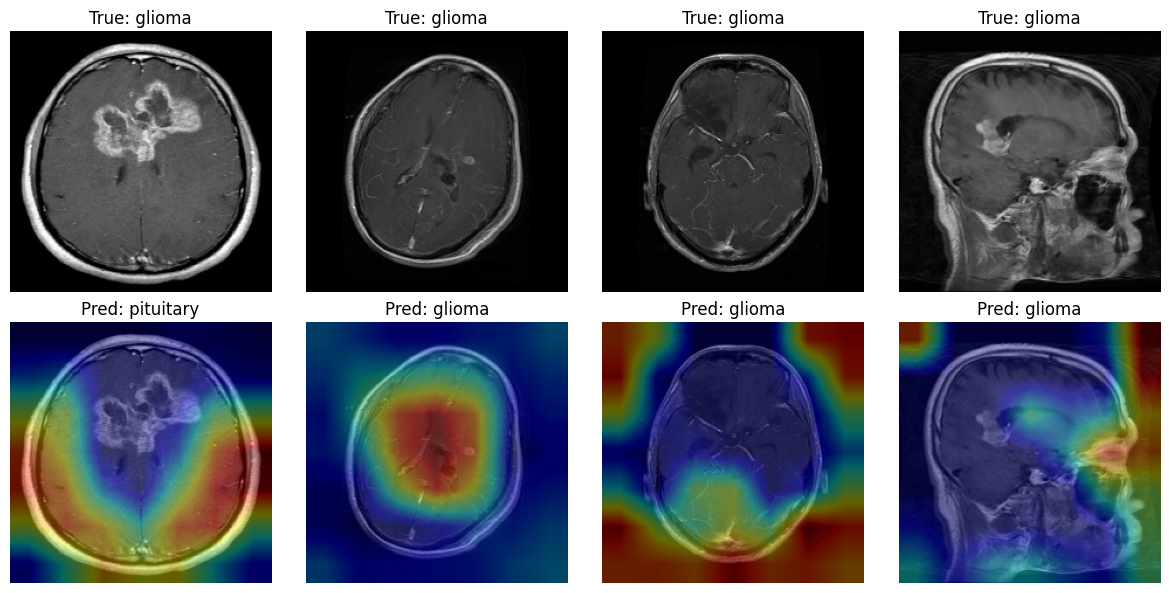

In [11]:
def gradcam(model, img_array, last_conv="top_conv"):
    base_model = model.get_layer("efficientnetb0")
    conv_model = tf.keras.Model(base_model.input, [base_model.get_layer(last_conv).output, base_model.output])
    with tf.GradientTape() as tape:
        conv_out, feats = conv_model(img_array)
        # rebuild the head on top of the base output
        x = feats
        for l in model.layers[3:]:
            x = l(x)
        idx = tf.argmax(x[0]); score = x[:, idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam) / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(idx)

imgs, labels = next(iter(test_ds))
plt.figure(figsize=(12, 6))
for i in range(4):
    img = imgs[i:i+1]
    cam, pred = gradcam(tl, img)
    cam = tf.image.resize(cam[..., None], IMG).numpy().squeeze()
    plt.subplot(2, 4, i + 1); plt.imshow(img[0].numpy().astype("uint8")); plt.axis("off")
    plt.title(f"True: {class_names[labels[i].numpy().argmax()]}")
    plt.subplot(2, 4, i + 5); plt.imshow(img[0].numpy().astype("uint8"))
    plt.imshow(cam, cmap="jet", alpha=0.4); plt.axis("off")
    plt.title(f"Pred: {class_names[pred]}")
plt.tight_layout(); plt.show()

**Save the final model**

In [12]:
tl.save("brain_tumor_efficientnetb0.keras")
cnn.save("brain_tumor_custom_cnn.keras")

In [13]:
loaded_tl  = tf.keras.models.load_model("brain_tumor_efficientnetb0.keras")
loaded_cnn = tf.keras.models.load_model("brain_tumor_custom_cnn.keras")

print("TL  test accuracy:", loaded_tl.evaluate(test_ds, verbose=0)[1])
print("CNN test accuracy:", loaded_cnn.evaluate(test_ds, verbose=0)[1])

TL  test accuracy: 0.8681250214576721
CNN test accuracy: 0.7943750023841858


Test a single prediction

In [14]:
import os
for f in ["brain_tumor_efficientnetb0.keras", "brain_tumor_custom_cnn.keras"]:
    print(f, "->", os.path.exists(f), f"{os.path.getsize(f)/1e6:.1f} MB" if os.path.exists(f) else "")

brain_tumor_efficientnetb0.keras -> True 31.0 MB
brain_tumor_custom_cnn.keras -> True 5.2 MB


In [15]:
loaded_tl  = tf.keras.models.load_model("brain_tumor_efficientnetb0.keras")
loaded_cnn = tf.keras.models.load_model("brain_tumor_custom_cnn.keras")

print("TL  test accuracy:", loaded_tl.evaluate(test_ds, verbose=0)[1])
print("CNN test accuracy:", loaded_cnn.evaluate(test_ds, verbose=0)[1])

TL  test accuracy: 0.8681250214576721
CNN test accuracy: 0.7943750023841858


In [16]:
imgs, labels = next(iter(test_ds))
pred = loaded_tl.predict(imgs[:1], verbose=0).argmax()
print("Predicted:", class_names[pred], "| True:", class_names[labels[0].numpy().argmax()])

Predicted: pituitary | True: glioma
